# Cervical Cancer Mortality Prediction with Machine Learning

Predicts **death within 1, 3, 5 and 10 years of diagnosis** in women with cervical cancer, using hospital-based
cancer registry data (Mato Grosso, Brazil). Two classifiers are compared (**Logistic Regression** and
**Random Forest**), each trained on the **original (imbalanced)** data and on **SMOTE-balanced** data.

| Step | What is done |
|---|---|
| 1. Setup | Imports and configuration |
| 2. Data | Load the Excel file and select variables |
| 3. Feature engineering | Recode categories to English, one-hot encode, rename features |
| 4. Exploration | Outcome distribution and correlation heatmap |
| 5. Modeling | For each horizon: stratified split, age scaling, grid search (5-fold CV), imbalanced vs. SMOTE |
| 6. Evaluation | Accuracy, balanced accuracy, precision, recall, specificity, NPV, F1, MCC, AUROC, AUC-PR, Brier |
| 7. Summary | Results table, confusion matrices and ROC curves |

> **Data are not included** in this repository (patient-level, confidential). See the README for the expected columns.

## 1. Setup

In [1]:
# Install dependencies (skip if already installed)
%pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline   # applies SMOTE inside each CV fold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             matthews_corrcoef, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve, auc)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

### Configuration

All experiment settings live here. The Random Forest grid has 216 combinations x 5 folds, so the full run
(4 horizons x 2 models x 2 data scenarios) can take a while; reduce `HORIZONS` or the grids to speed it up.

In [5]:
# --- Paths ---
DATA_FILE = Path("C:/Users/sanch/OneDrive/Documentos/Paper 2025/ML Cancer cervical/Mortality_CC_ML_Survival_28092026.xlsx")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

# --- Experiment ---
HORIZONS = [1, 3, 5, 10]   # years after diagnosis
SEED = 42
TEST_SIZE = 0.25
CV_FOLDS = 5
SCORING = None             # None = accuracy (as in the original analysis); "roc_auc" is a good alternative
USE_OBSERVED_FILTER = False  # True = keep only patients with observed_{h}yr == 1 (complete follow-up)

# --- Figures ---
FIG_FORMAT = "png"         # use "tiff" for publication
FIG_DPI = 300

# --- Hyperparameter grids ---
PARAM_GRID_LR = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "max_iter": [100, 500],
}
PARAM_GRID_RF = {
    "n_estimators": [100, 200, 500],
    "max_depth": [4, 8, 12],
    "min_samples_leaf": [1, 5, 10],
    "min_samples_split": [2, 5, 10, 30],
    "criterion": ["gini", "entropy"],
}

## 2. Data

Load the Excel file and keep only the variables used in the analysis:
age, race, city of residence, education, histopathology (`Categoria_Morfologia`) and disease extent (`Extensao`),
plus the binary targets `death_{h}yr` for each horizon.

In [6]:
raw = pd.read_excel(DATA_FILE)

predictor_cols = ["Idade", "Race", "City_residence", "education", "Categoria_Morfologia", "Extensao"]
target_cols = [f"death_{h}yr" for h in HORIZONS]
observed_cols = [f"observed_{h}yr" for h in HORIZONS if f"observed_{h}yr" in raw.columns]

df = raw[predictor_cols + target_cols + observed_cols].copy()
print("Rows:", len(df))
df.info()

Rows: 1682
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Idade                 1682 non-null   int64  
 1   Race                  1682 non-null   object 
 2   City_residence        1682 non-null   object 
 3   education             1682 non-null   object 
 4   Categoria_Morfologia  1682 non-null   object 
 5   Extensao              1682 non-null   object 
 6   death_1yr             1682 non-null   int64  
 7   death_3yr             1682 non-null   int64  
 8   death_5yr             1547 non-null   float64
 9   death_10yr            1161 non-null   float64
 10  observed_1yr          1682 non-null   int64  
 11  observed_3yr          1682 non-null   int64  
 12  observed_5yr          1682 non-null   int64  
 13  observed_10yr         1682 non-null   int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 184.1+ KB


## 3. Feature engineering

Registry values (Portuguese) are mapped to English labels. Each categorical variable is an **ordered categorical**
whose **first category is the reference level** dropped during one-hot encoding.

In [7]:
# --- Age at diagnosis ---
print(df["Idade"].describe())

# --- Race (reference: Other/Unknown) ---
df["Race"] = (df["Race"].map({"Preta": "Black", "Branca": "White"}).fillna("Other/Unknown"))
df["Race"] = pd.Categorical(df["Race"], categories=["Other/Unknown", "Black", "White"], ordered=True)

# --- Education (reference: No information) ---
df["education"] = df["education"].map({
    "Sem informação": "No information",
    "Sem escolaridade": "No formal education",
    "Fundamental": "Elementary",
    "Médio": "Middle school",
    "Superior": "High education",
})
df["education"] = pd.Categorical(
    df["education"],
    categories=["No information", "No formal education", "Elementary", "Middle school", "High education"],
    ordered=True)

# --- City of residence (reference: Others) ---
df["City_residence"] = df["City_residence"].map({
    "Outros": "Others", "Cuiaba": "Cuiabá", "Varzea Grande": "Várzea Grande",
    "Rondonopolis": "Rondonópolis", "Sinop": "Sinop",
})
df["City_residence"] = pd.Categorical(
    df["City_residence"],
    categories=["Others", "Cuiabá", "Várzea Grande", "Rondonópolis", "Sinop"], ordered=True)

# --- Histopathology type (reference: Others) ---
df["Histopathology type"] = df["Categoria_Morfologia"].map({
    "Malignant neoplasms": "Malignant neoplasms",
    "Squamous cell carcinoma": "Squamous cell carcinoma",
    "Adenocarcinoma": "Adenocarcinoma",
    "Outros": "Others",
})
df["Histopathology type"] = pd.Categorical(
    df["Histopathology type"],
    categories=["Others", "Squamous cell carcinoma", "Adenocarcinoma", "Malignant neoplasms"], ordered=True)

# --- Stage at diagnosis (reference: In situ); patients without stage information are excluded ---
df["Stage"] = df["Extensao"].map({
    "In Situ": "In situ", "Localizado": "Localized",
    "Metástase": "Metastatic", "Sem informação": "No information",
})
n_before = len(df)
df = df[df["Stage"] != "No information"].copy()
print(f"Removed {n_before - len(df)} patients with no stage information")
df["Stage"] = pd.Categorical(df["Stage"], categories=["In situ", "Localized", "Metastatic"], ordered=True)

# Sanity check: unmapped registry values become NaN; those rows would silently fall into the
# reference category, so they are dropped and reported.
model_vars = ["Idade", "Race", "City_residence", "education", "Histopathology type", "Stage"]
print("\nMissing values in predictors:\n", df[model_vars].isna().sum())
n_before = len(df)
df = df.dropna(subset=model_vars).copy()
print(f"Dropped {n_before - len(df)} rows with missing predictors | final n = {len(df)}")

for col in ["Race", "education", "City_residence", "Histopathology type", "Stage"]:
    print(f"\n{col}:")
    print(df[col].value_counts(sort=False))

count    1682.000000
mean       41.087396
std        14.415442
min        17.000000
25%        30.000000
50%        38.000000
75%        50.000000
max       101.000000
Name: Idade, dtype: float64
Removed 0 patients with no stage information

Missing values in predictors:
 Idade                  0
Race                   0
City_residence         0
education              0
Histopathology type    0
Stage                  0
dtype: int64
Dropped 0 rows with missing predictors | final n = 1682

Race:
Race
Other/Unknown    1154
Black              91
White             437
Name: count, dtype: int64

education:
education
No information         1504
No formal education      21
Elementary              100
Middle school            43
High education           14
Name: count, dtype: int64

City_residence:
City_residence
Others           940
Cuiabá           426
Várzea Grande    162
Rondonópolis     112
Sinop             42
Name: count, dtype: int64

Histopathology type:
Histopathology type
Others     

### 3.1 One-hot encoding and readable feature names

In [8]:
CATEGORICAL = ["Race", "City_residence", "education", "Histopathology type", "Stage"]

# One-hot encode (the first category of each variable is the reference and is dropped)
X = pd.get_dummies(df[CATEGORICAL], drop_first=True).astype(int)

# Put age first, under a readable name
X.insert(0, "Age at Diagnosis", df["Idade"])

FEATURE_NAMES = {
    "Race_Black": "Race (Black)",
    "Race_White": "Race (White)",
    "City_residence_Cuiabá": "Residence (Cuiabá)",
    "City_residence_Várzea Grande": "Residence (Várzea Grande)",
    "City_residence_Rondonópolis": "Residence (Rondonópolis)",
    "City_residence_Sinop": "Residence (Sinop)",
    "education_No formal education": "Education (No formal education)",
    "education_Elementary": "Education (Elementary)",
    "education_Middle school": "Education (Middle school)",
    "education_High education": "Education (High education)",
    "Histopathology type_Squamous cell carcinoma": "Histopathology (Squamous Cell Carcinoma)",
    "Histopathology type_Adenocarcinoma": "Histopathology (Adenocarcinoma)",
    "Histopathology type_Malignant neoplasms": "Histopathology (Malignant Neoplasms)",
    "Stage_Localized": "Cancer Stage (Localized)",
    "Stage_Metastatic": "Cancer Stage (Metastatic)",
}
X = X.rename(columns=FEATURE_NAMES)

print("Feature matrix:", X.shape)
print(X.columns.tolist())

Feature matrix: (1682, 16)
['Age at Diagnosis', 'Race (Black)', 'Race (White)', 'Residence (Cuiabá)', 'Residence (Várzea Grande)', 'Residence (Rondonópolis)', 'Residence (Sinop)', 'Education (No formal education)', 'Education (Elementary)', 'Education (Middle school)', 'Education (High education)', 'Histopathology (Squamous Cell Carcinoma)', 'Histopathology (Adenocarcinoma)', 'Histopathology (Malignant Neoplasms)', 'Cancer Stage (Localized)', 'Cancer Stage (Metastatic)']


## 4. Exploration

### 4.1 Outcome distribution by horizon

In [9]:
dist = pd.DataFrame({
    f"{h} year(s)": df[f"death_{h}yr"].value_counts(dropna=False) for h in HORIZONS
}).fillna(0).astype(int)
dist.index.name = "death (0 = alive, 1 = dead, NaN = missing)"
dist

,1 year(s),3 year(s),5 year(s),10 year(s)
"death (0 = alive, 1 = dead, NaN = missing)",,,,
0.0,1604,1536,1377,970
1.0,78,146,170,191
NaN,0,0,135,521


## Handling censored cases at 5 and 10 years

At 1 and 3 years there are no NaN values, so those horizons are straightforward. At 5 and 10 years, the NaN values (135 and 521) are censored patients: they did not die before the horizon, but they were not followed up to it either, so their status at the horizon is unknown.

Why not the simple fixes

Counting them as “alive” underestimates mortality.
Dropping them biases the sample. Much of the censoring is administrative (follow-up ends 2021-12-24), so recently diagnosed patients are removed disproportionately.

Recommended approach: IPCW (inverse probability of censoring weighting)

### 4.2 Correlation heatmap

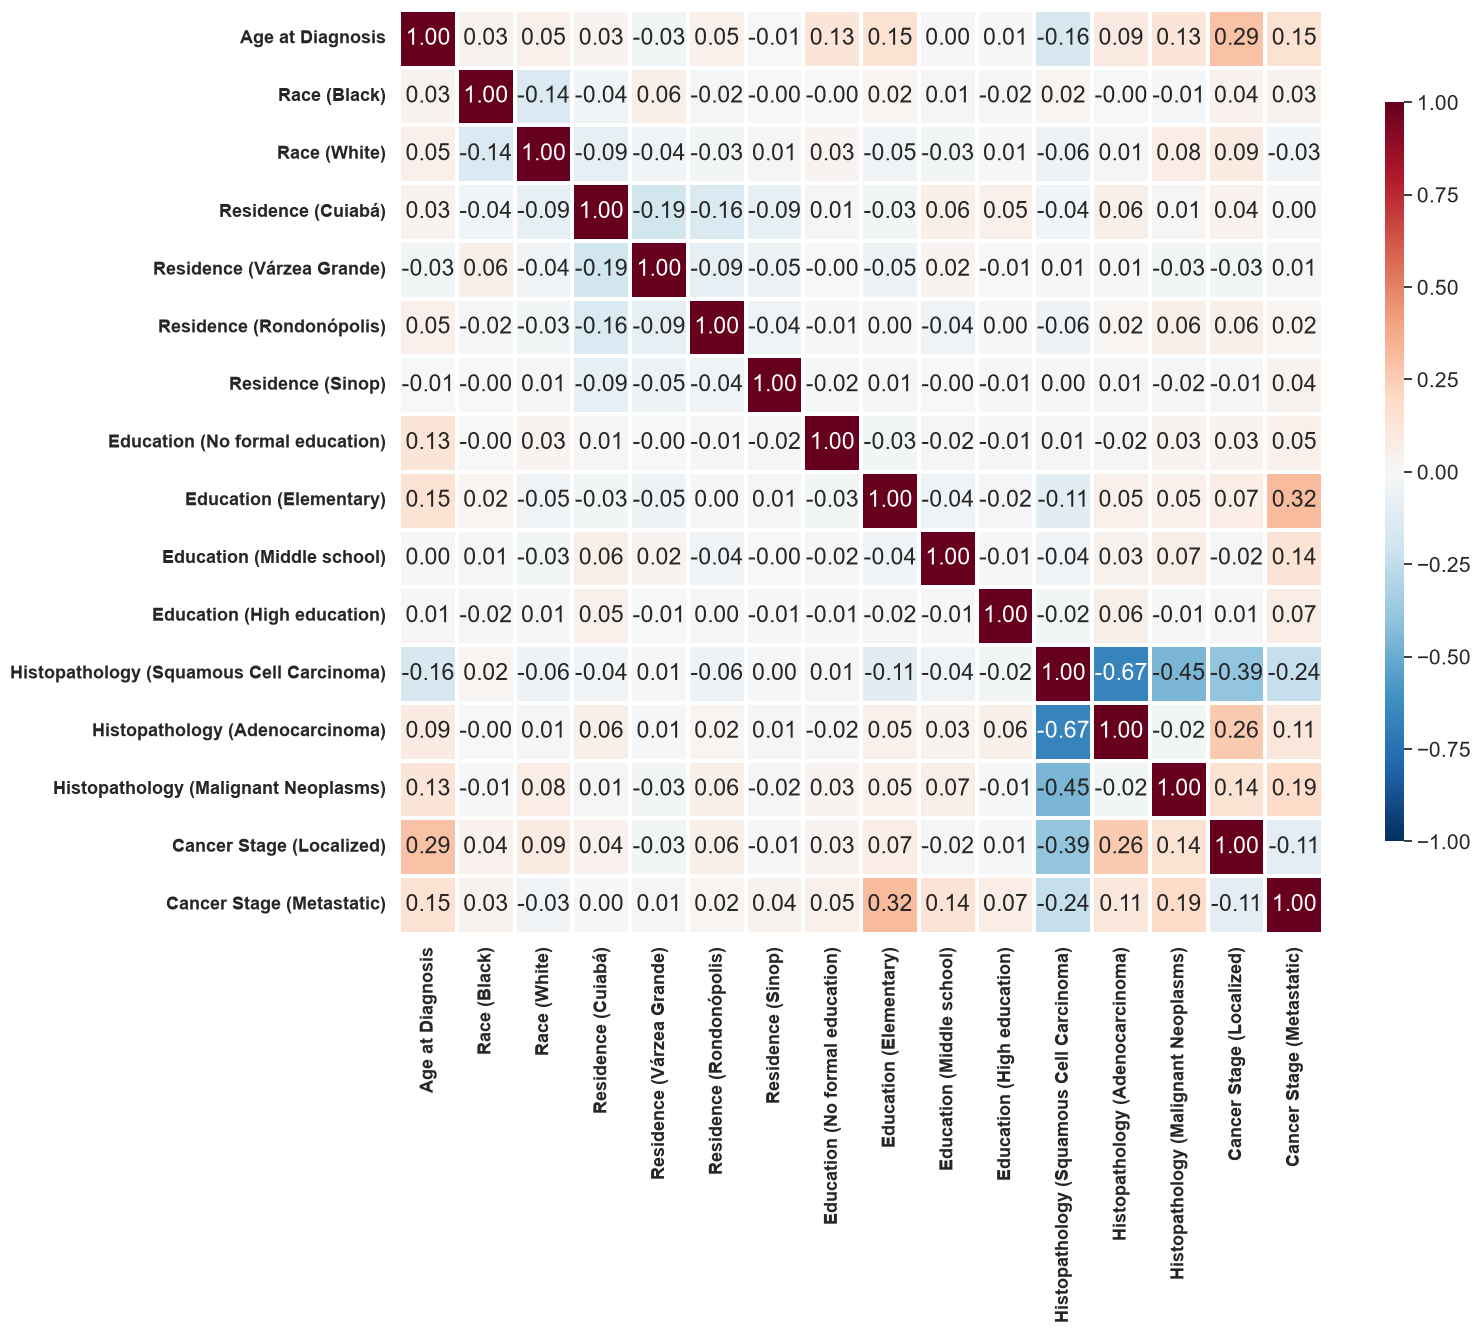

In [10]:
corr = X.corr()

sns.set_theme(style="white", font_scale=1.4)
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=True, cmap="RdBu_r", fmt=".2f", linewidths=1.5,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8, "aspect": 40})
plt.xticks(rotation=90, fontsize=13, fontweight="bold")
plt.yticks(rotation=0, fontsize=13, fontweight="bold")
sns.despine(left=True, bottom=True)
plt.savefig(OUT_DIR / f"heatmap_correlation.{FIG_FORMAT}", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 5. Modeling helpers

* **Split:** stratified 75/25 train/test, fixed seed.
* **Scaling:** only `Age at Diagnosis` is standardized; the scaler is **fitted on the training set only**.
* **Imbalanced scenario:** grid search directly on the training data.
* **SMOTE scenario:** SMOTE is placed **inside the cross-validation pipeline**, so synthetic samples are
  created only from each training fold (applying SMOTE before CV would leak information into the validation folds).
* **Evaluation:** always on the untouched test set.

In [11]:
def get_horizon_data(h):
    """Return features and binary target for a horizon (rows with a valid target)."""
    y = df[f"death_{h}yr"]
    mask = y.notna()
    if USE_OBSERVED_FILTER and f"observed_{h}yr" in df.columns:
        mask &= df[f"observed_{h}yr"] == 1
    return X.loc[mask].copy(), y.loc[mask].astype(int)


def split_and_scale(X_h, y_h):
    """Stratified train/test split and age standardization (fitted on train only)."""
    X_train, X_test, y_train, y_test = train_test_split(
        X_h, y_h, test_size=TEST_SIZE, random_state=SEED, stratify=y_h)
    scaler = StandardScaler()
    X_train["Age at Diagnosis"] = scaler.fit_transform(X_train[["Age at Diagnosis"]])
    X_test["Age at Diagnosis"] = scaler.transform(X_test[["Age at Diagnosis"]])
    return X_train, X_test, y_train, y_test


def make_search(model_name, balanced):
    """Grid search (stratified K-fold) for a model, optionally with SMOTE inside the CV."""
    if model_name == "Logistic Regression":
        estimator, grid = LogisticRegression(), PARAM_GRID_LR
    else:
        estimator, grid = RandomForestClassifier(random_state=SEED), PARAM_GRID_RF

    if balanced:
        estimator = ImbPipeline([("smote", SMOTE(random_state=SEED)), ("clf", estimator)])
        grid = {f"clf__{k}": v for k, v in grid.items()}

    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    return GridSearchCV(estimator, grid, cv=cv, scoring=SCORING, n_jobs=-1)


def evaluate(y_true, y_pred, y_proba):
    """Compute test-set metrics."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_proba)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_ppv": precision_score(y_true, y_pred, zero_division=0),
        "recall_sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "npv": tn / (tn + fn) if (tn + fn) else np.nan,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "auroc": roc_auc_score(y_true, y_proba),
        "auc_pr": auc(recall_vals, precision_vals),
        "brier": brier_score_loss(y_true, y_proba),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
    }


def plot_class_distribution(y_original, y_balanced, h):
    """Bar charts of the training-set class distribution, before and after SMOTE."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, y, title in [(axes[0], y_original, "Original (imbalanced)"),
                         (axes[1], y_balanced, "SMOTE-balanced")]:
        counts = y.value_counts().reindex([0, 1], fill_value=0)
        pct = counts / counts.sum() * 100
        bars = ax.bar(["Alive (0)", "Deceased (1)"], counts.values, color=["#66c2a5", "#fc8d62"], width=0.6)
        for bar, n, p in zip(bars, counts.values, pct.values):
            ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n} ({p:.1f}%)",
                    ha="center", va="bottom", fontsize=11, fontweight="bold")
        ax.set_title(f"{title}: {h}-year", fontweight="bold")
        ax.set_ylabel("Number of cases")
        sns.despine(ax=ax)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"class_distribution_{h}yr.{FIG_FORMAT}", dpi=FIG_DPI, bbox_inches="tight")
    plt.show()

## 6. Run the experiments

For each horizon, four models are trained and evaluated on the test set:
Logistic Regression and Random Forest, each on imbalanced and SMOTE-balanced data.
Training metrics are computed on the **original** training set, so they are comparable across scenarios.

HORIZON: 1 year(s)
Class counts: {0: 1604, 1: 78}


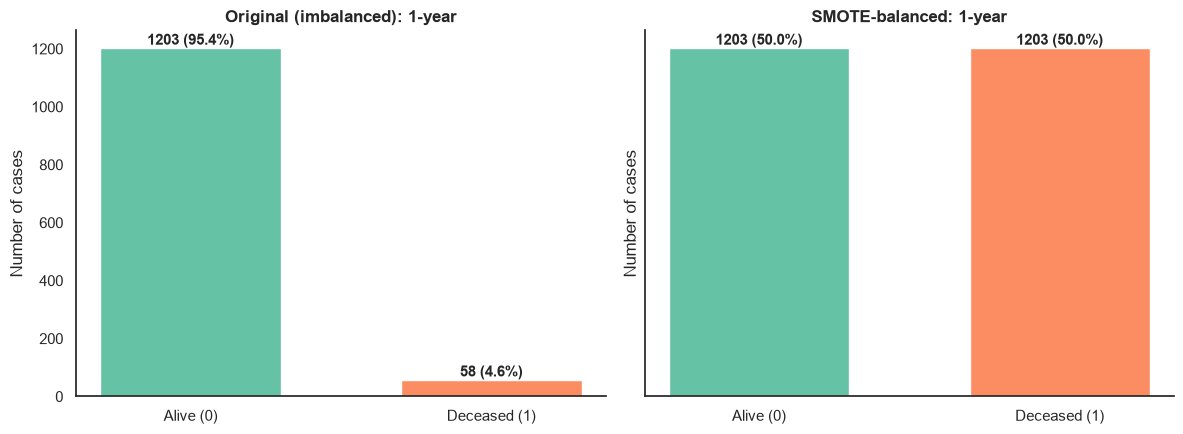


Training Logistic Regression | Imbalanced ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


  best params: {'C': 1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'}
  test AUROC = 0.898 | balanced acc = 0.549 | recall = 0.100 | specificity = 0.998

Training Logistic Regression | SMOTE ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


  best params: {'clf__C': 1, 'clf__max_iter': 100, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
  test AUROC = 0.820 | balanced acc = 0.699 | recall = 0.550 | specificity = 0.848

Training Random Forest | Imbalanced ...
  best params: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
  test AUROC = 0.894 | balanced acc = 0.524 | recall = 0.050 | specificity = 0.998

Training Random Forest | SMOTE ...
  best params: {'clf__criterion': 'gini', 'clf__max_depth': 12, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
  test AUROC = 0.777 | balanced acc = 0.668 | recall = 0.450 | specificity = 0.885


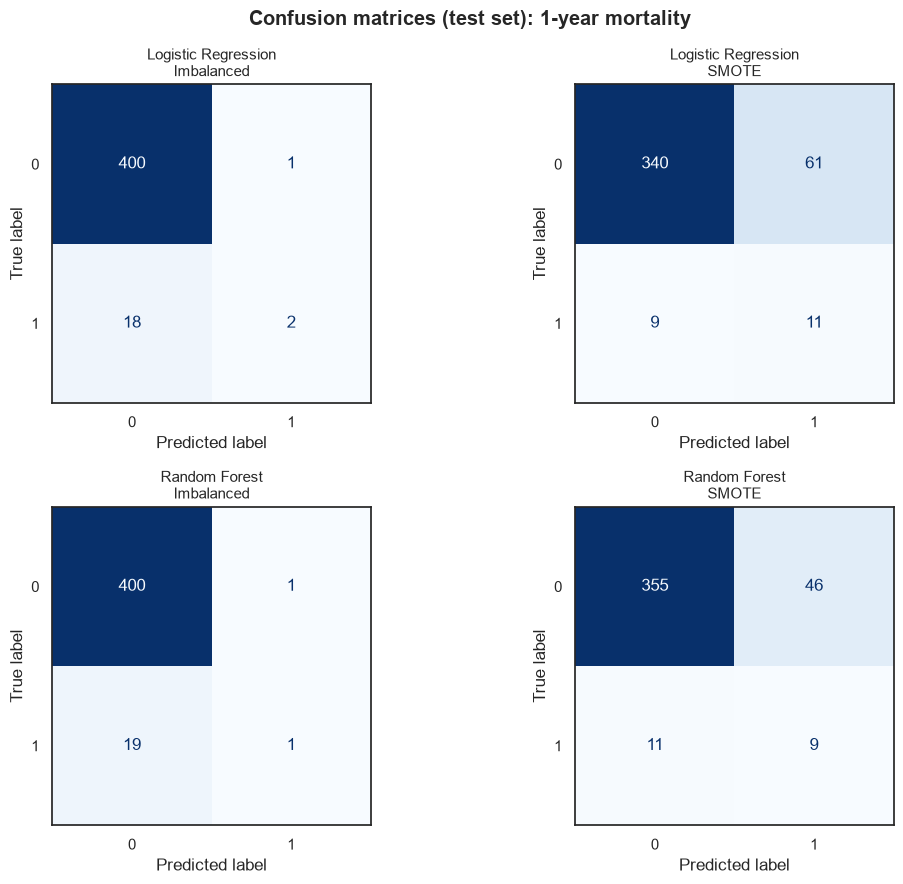

HORIZON: 3 year(s)
Class counts: {0: 1536, 1: 146}


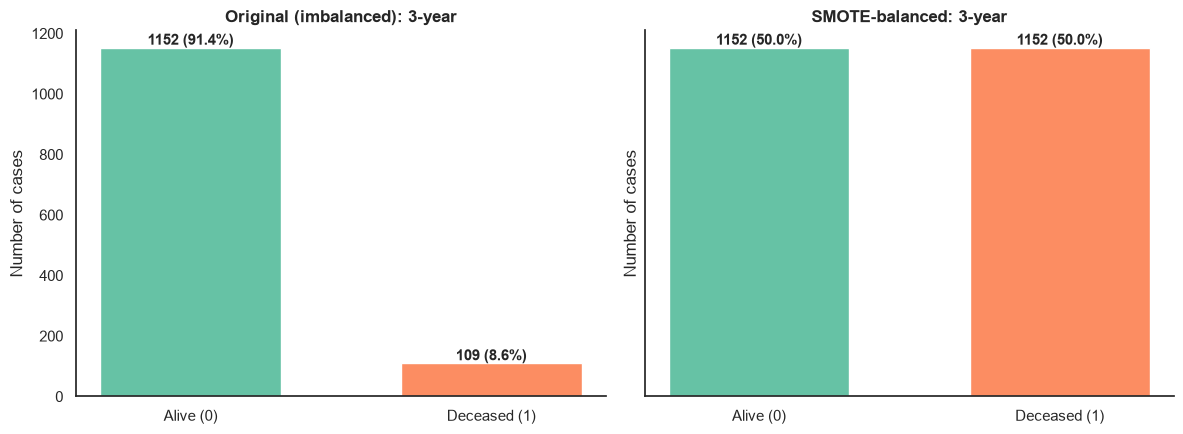


Training Logistic Regression | Imbalanced ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


  best params: {'C': 1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'}
  test AUROC = 0.890 | balanced acc = 0.698 | recall = 0.432 | specificity = 0.964

Training Logistic Regression | SMOTE ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


  best params: {'clf__C': 10, 'clf__max_iter': 100, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
  test AUROC = 0.853 | balanced acc = 0.805 | recall = 0.784 | specificity = 0.826

Training Random Forest | Imbalanced ...
  best params: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
  test AUROC = 0.884 | balanced acc = 0.676 | recall = 0.378 | specificity = 0.974

Training Random Forest | SMOTE ...
  best params: {'clf__criterion': 'entropy', 'clf__max_depth': 12, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 100}
  test AUROC = 0.831 | balanced acc = 0.759 | recall = 0.649 | specificity = 0.870


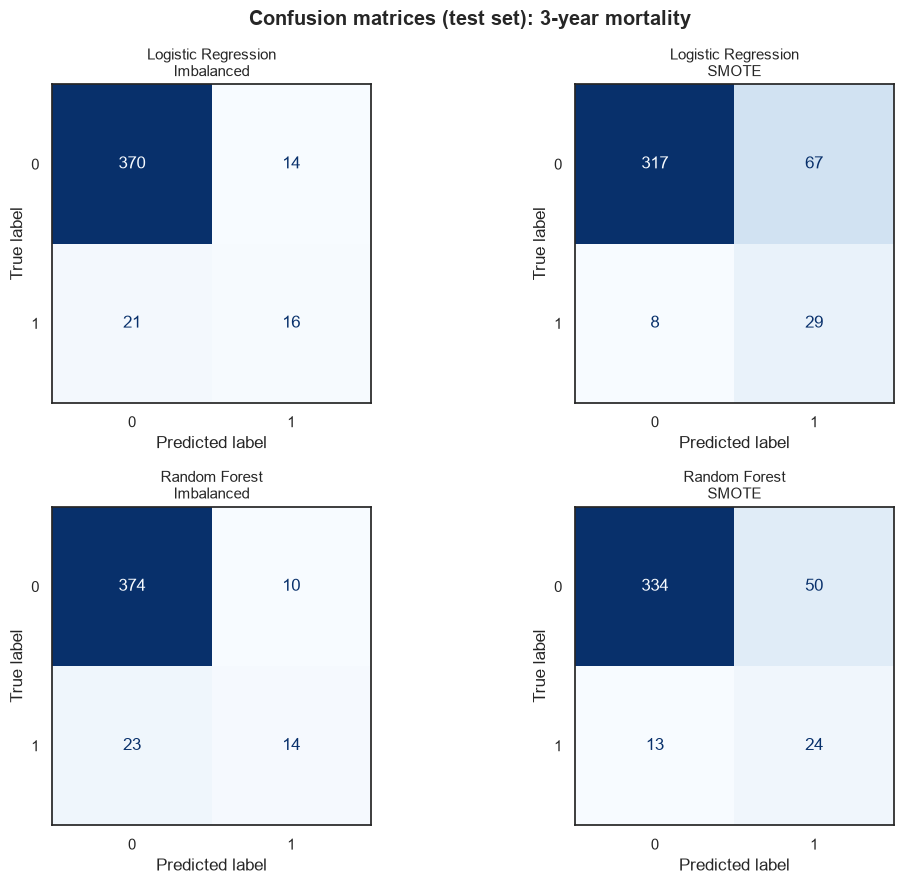

HORIZON: 5 year(s)
Class counts: {0: 1377, 1: 170}


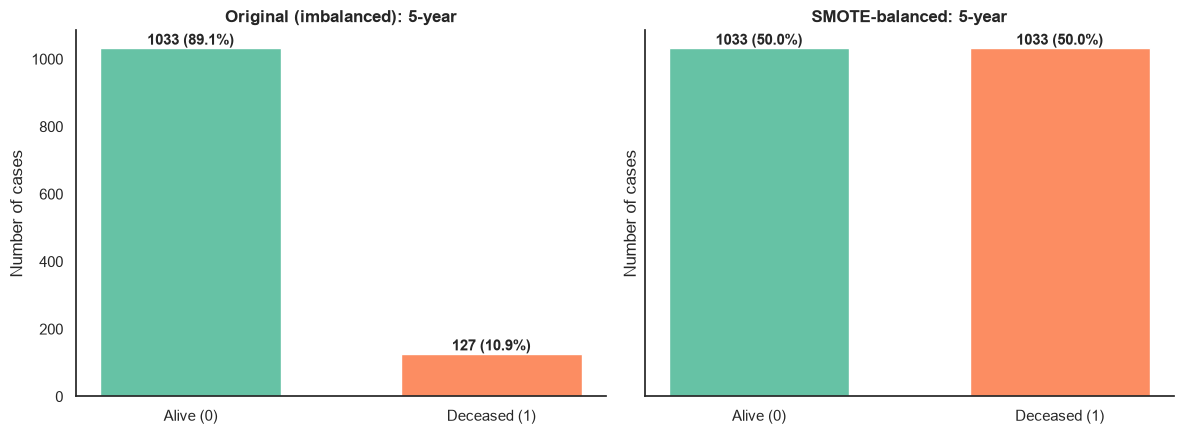


Training Logistic Regression | Imbalanced ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


  best params: {'C': 1, 'max_iter': 100, 'penalty': 'l2', 'solver': 'liblinear'}
  test AUROC = 0.919 | balanced acc = 0.696 | recall = 0.419 | specificity = 0.974

Training Logistic Regression | SMOTE ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


  best params: {'clf__C': 10, 'clf__max_iter': 100, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
  test AUROC = 0.865 | balanced acc = 0.801 | recall = 0.791 | specificity = 0.811

Training Random Forest | Imbalanced ...
  best params: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 100}
  test AUROC = 0.915 | balanced acc = 0.695 | recall = 0.419 | specificity = 0.971

Training Random Forest | SMOTE ...
  best params: {'clf__criterion': 'entropy', 'clf__max_depth': 4, 'clf__min_samples_leaf': 10, 'clf__min_samples_split': 30, 'clf__n_estimators': 100}
  test AUROC = 0.874 | balanced acc = 0.837 | recall = 0.814 | specificity = 0.860


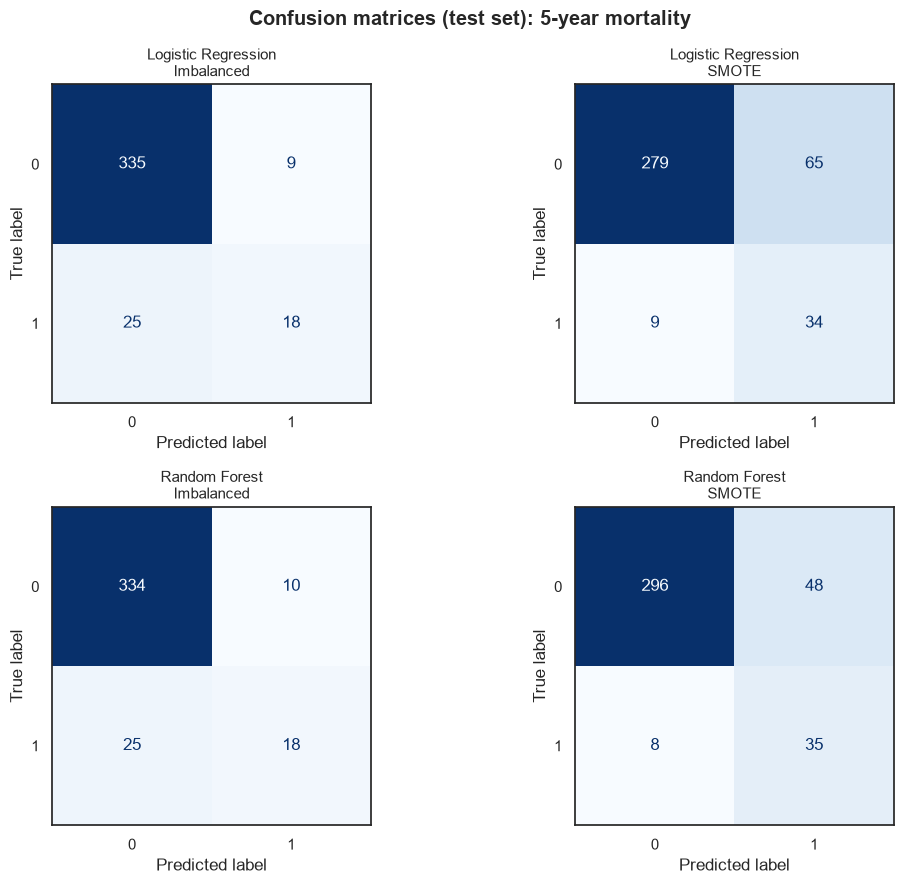

HORIZON: 10 year(s)
Class counts: {0: 970, 1: 191}


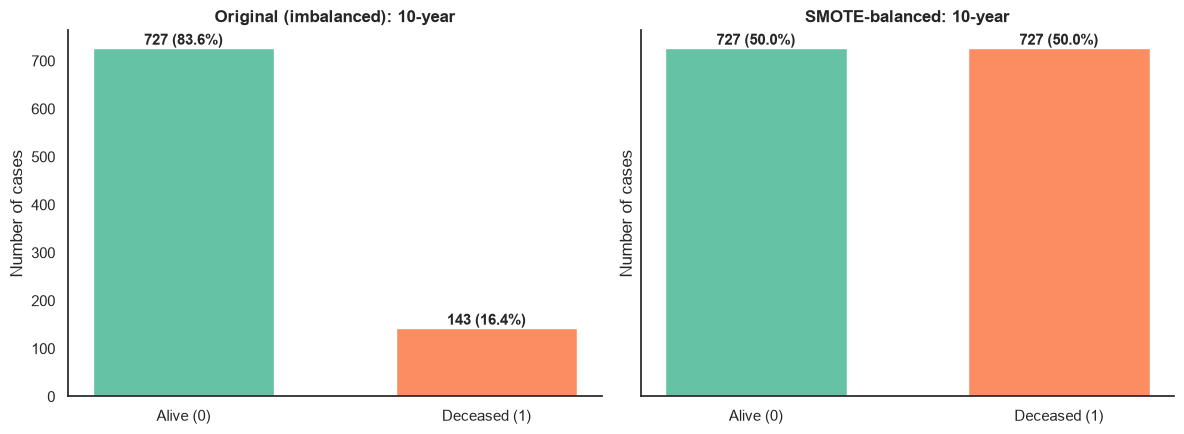


Training Logistic Regression | Imbalanced ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


  best params: {'C': 1, 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'}
  test AUROC = 0.933 | balanced acc = 0.731 | recall = 0.479 | specificity = 0.984

Training Logistic Regression | SMOTE ...


C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\sanch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


  best params: {'clf__C': 1, 'clf__max_iter': 100, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
  test AUROC = 0.909 | balanced acc = 0.828 | recall = 0.812 | specificity = 0.844

Training Random Forest | Imbalanced ...
  best params: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 30, 'n_estimators': 100}
  test AUROC = 0.918 | balanced acc = 0.765 | recall = 0.562 | specificity = 0.967

Training Random Forest | SMOTE ...
  best params: {'clf__criterion': 'entropy', 'clf__max_depth': 4, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 30, 'clf__n_estimators': 200}
  test AUROC = 0.905 | balanced acc = 0.838 | recall = 0.812 | specificity = 0.864


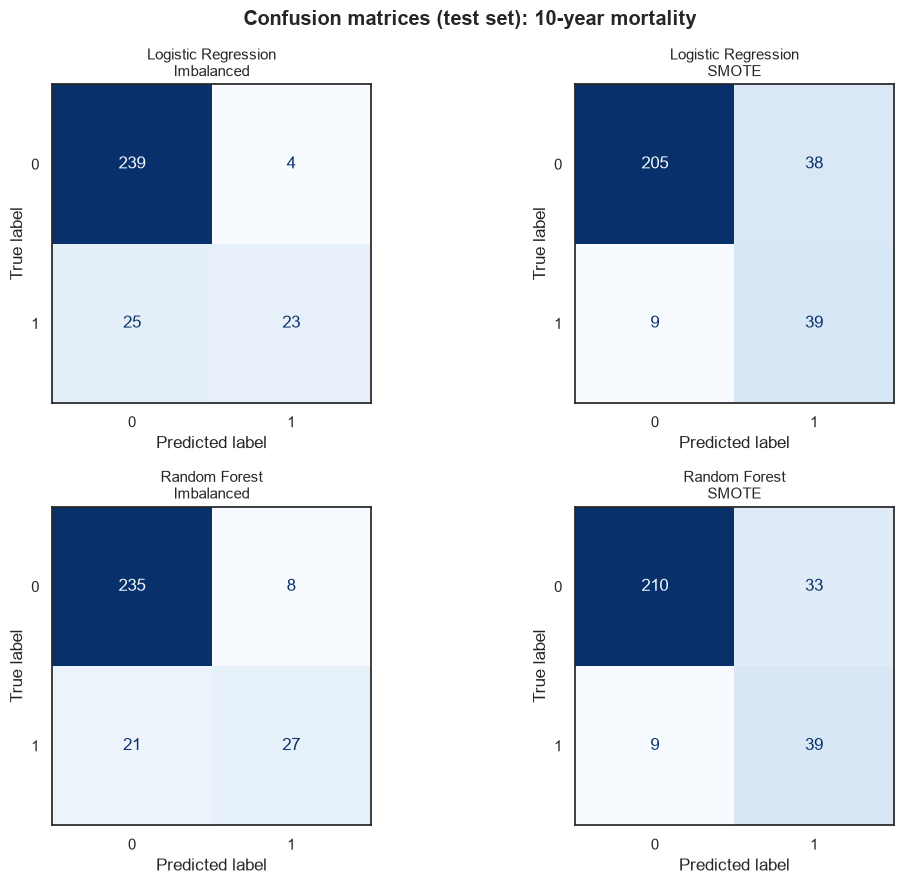

In [12]:
sns.set_theme(style="white", font_scale=1.0)

results = []      # one row per (horizon, model, data scenario)
roc_store = {}    # ROC curves for the summary plot
n_pos_min = CV_FOLDS * 2

for h in HORIZONS:
    print("=" * 70)
    print(f"HORIZON: {h} year(s)")
    print("=" * 70)

    X_h, y_h = get_horizon_data(h)
    print("Class counts:", y_h.value_counts().to_dict())
    if y_h.nunique() < 2 or y_h.value_counts().min() < n_pos_min:
        print("Too few cases in one class; skipping this horizon.\n")
        continue

    X_train, X_test, y_train, y_test = split_and_scale(X_h, y_h)

    # Show the class distribution before and after SMOTE (illustration only)
    _, y_smote = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
    plot_class_distribution(y_train, y_smote, h)

    fig_cm, axes_cm = plt.subplots(2, 2, figsize=(11, 9))
    axes_cm = axes_cm.ravel()
    i_ax = 0

    for model_name in ["Logistic Regression", "Random Forest"]:
        for balanced in [False, True]:
            scenario = "SMOTE" if balanced else "Imbalanced"
            print(f"\nTraining {model_name} | {scenario} ...")

            search = make_search(model_name, balanced)
            search.fit(X_train, y_train)
            best = search.best_estimator_

            # Predictions and probabilities
            y_pred_train = best.predict(X_train)
            y_pred = best.predict(X_test)
            y_proba = best.predict_proba(X_test)[:, 1]

            metrics = evaluate(y_test, y_pred, y_proba)
            results.append({
                "horizon_years": h, "model": model_name, "data": scenario,
                "n_train": len(y_train), "n_test": len(y_test),
                "cv_best_score": search.best_score_,
                "train_accuracy": accuracy_score(y_train, y_pred_train),
                "train_f1_macro": f1_score(y_train, y_pred_train, average="macro"),
                "test_f1_macro": f1_score(y_test, y_pred, average="macro"),
                **metrics,
                "best_params": str(search.best_params_),
            })
            print(f"  best params: {search.best_params_}")
            print(f"  test AUROC = {metrics['auroc']:.3f} | balanced acc = {metrics['balanced_accuracy']:.3f}"
                  f" | recall = {metrics['recall_sensitivity']:.3f} | specificity = {metrics['specificity']:.3f}")

            # Store the ROC curve and draw the confusion matrix
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            roc_store[(h, model_name, scenario)] = (fpr, tpr, metrics["auroc"])
            ConfusionMatrixDisplay.from_predictions(
                y_test, y_pred, ax=axes_cm[i_ax], colorbar=False, cmap="Blues")
            axes_cm[i_ax].set_title(f"{model_name}\n{scenario}", fontsize=11)
            i_ax += 1

    fig_cm.suptitle(f"Confusion matrices (test set): {h}-year mortality", fontweight="bold")
    fig_cm.tight_layout()
    fig_cm.savefig(OUT_DIR / f"confusion_matrices_{h}yr.{FIG_FORMAT}", dpi=FIG_DPI, bbox_inches="tight")
    plt.show()

## 7. Results summary

### 7.1 Full metrics table

In [13]:
results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "model_results.csv", index=False)

metric_cols = ["accuracy", "balanced_accuracy", "precision_ppv", "recall_sensitivity", "specificity",
               "npv", "f1", "mcc", "auroc", "auc_pr", "brier"]
display(results_df[["horizon_years", "model", "data"] + metric_cols]
        .style.format({c: "{:.3f}" for c in metric_cols})
        .background_gradient(subset=["auroc", "balanced_accuracy"], cmap="Greens"))

,horizon_years,model,data,accuracy,balanced_accuracy,precision_ppv,recall_sensitivity,specificity,npv,f1,mcc,auroc,auc_pr,brier
0,1,Logistic Regression,Imbalanced,0.955,0.549,0.667,0.100,0.998,0.957,0.174,0.247,0.898,0.253,0.040
1,1,Logistic Regression,SMOTE,0.834,0.699,0.153,0.550,0.848,0.974,0.239,0.225,0.820,0.200,0.127
2,1,Random Forest,Imbalanced,0.952,0.524,0.500,0.050,0.998,0.955,0.091,0.147,0.894,0.291,0.039
3,1,Random Forest,SMOTE,0.865,0.668,0.164,0.450,0.885,0.970,0.240,0.212,0.777,0.169,0.096
4,3,Logistic Regression,Imbalanced,0.917,0.698,0.533,0.432,0.964,0.946,0.478,0.436,0.890,0.482,0.061
5,3,Logistic Regression,SMOTE,0.822,0.805,0.302,0.784,0.826,0.975,0.436,0.411,0.853,0.373,0.134
6,3,Random Forest,Imbalanced,0.922,0.676,0.583,0.378,0.974,0.942,0.459,0.430,0.884,0.545,0.056
7,3,Random Forest,SMOTE,0.850,0.759,0.324,0.649,0.870,0.963,0.432,0.386,0.831,0.338,0.118
8,5,Logistic Regression,Imbalanced,0.912,0.696,0.667,0.419,0.974,0.931,0.514,0.484,0.919,0.605,0.065
9,5,Logistic Regression,SMOTE,0.809,0.801,0.343,0.791,0.811,0.969,0.479,0.433,0.865,0.478,0.145


### 7.2 AUROC by horizon, model and data scenario

In [14]:
auroc_table = results_df.pivot_table(index=["model", "data"], columns="horizon_years", values="auroc")
display(auroc_table.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None))

### 7.3 ROC curves

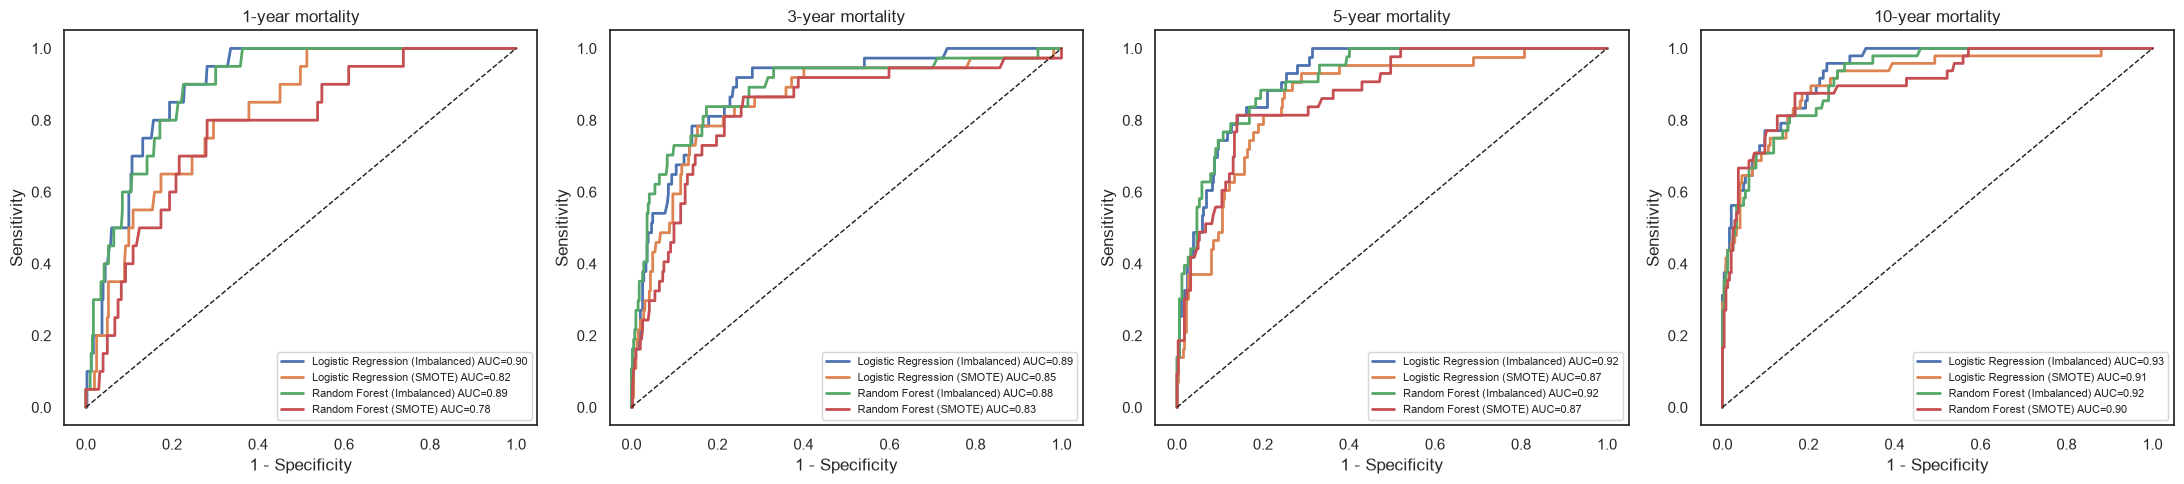

In [15]:
horizons_run = sorted(results_df["horizon_years"].unique())
fig, axes = plt.subplots(1, len(horizons_run), figsize=(5.5 * len(horizons_run), 5), squeeze=False)

for ax, h in zip(axes[0], horizons_run):
    for (hh, model_name, scenario), (fpr, tpr, auroc) in roc_store.items():
        if hh == h:
            ax.plot(fpr, tpr, lw=2, label=f"{model_name} ({scenario}) AUC={auroc:.2f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=f"{h}-year mortality", xlabel="1 - Specificity", ylabel="Sensitivity")
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(OUT_DIR / f"roc_curves.{FIG_FORMAT}", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Notes and next steps
* With a rare outcome (e.g. 1-year mortality), accuracy is misleading: prioritize **AUROC, AUC-PR, balanced accuracy,
  sensitivity and MCC**.
* Class probabilities from models trained on SMOTE data are not calibrated; check the Brier score or add calibration.
* Possible extensions: gradient boosting (XGBoost/LightGBM), SHAP for interpretability, and time-to-event models
  (Cox, random survival forests) that use censored follow-up instead of fixed-horizon binary labels.